In [19]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib import gridspec
%config InlineBackend.figure_format = 'retina'
plt.rcParams.update(
    {
        'text.usetex': False,
        'font.family': 'stixgeneral',
        'mathtext.fontset': 'stix',
    }
)
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['image.origin'] = 'lower'
plt.rcParams["font.family"] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Tahoma', 'Verdana', 'Lucida Grande', 'DejaVu Sans']

In [15]:
ra,de,sn,rae,dee = np.loadtxt("offsets.txt").transpose()

ra_stat = 0.45*26.9/sn
de_stat = 0.45*15.6/sn
ra_t = np.sqrt(ra_stat**2.+rae**2.)
de_t = np.sqrt(de_stat**2.+dee**2.)

Text(0.5, 0, 'Number')

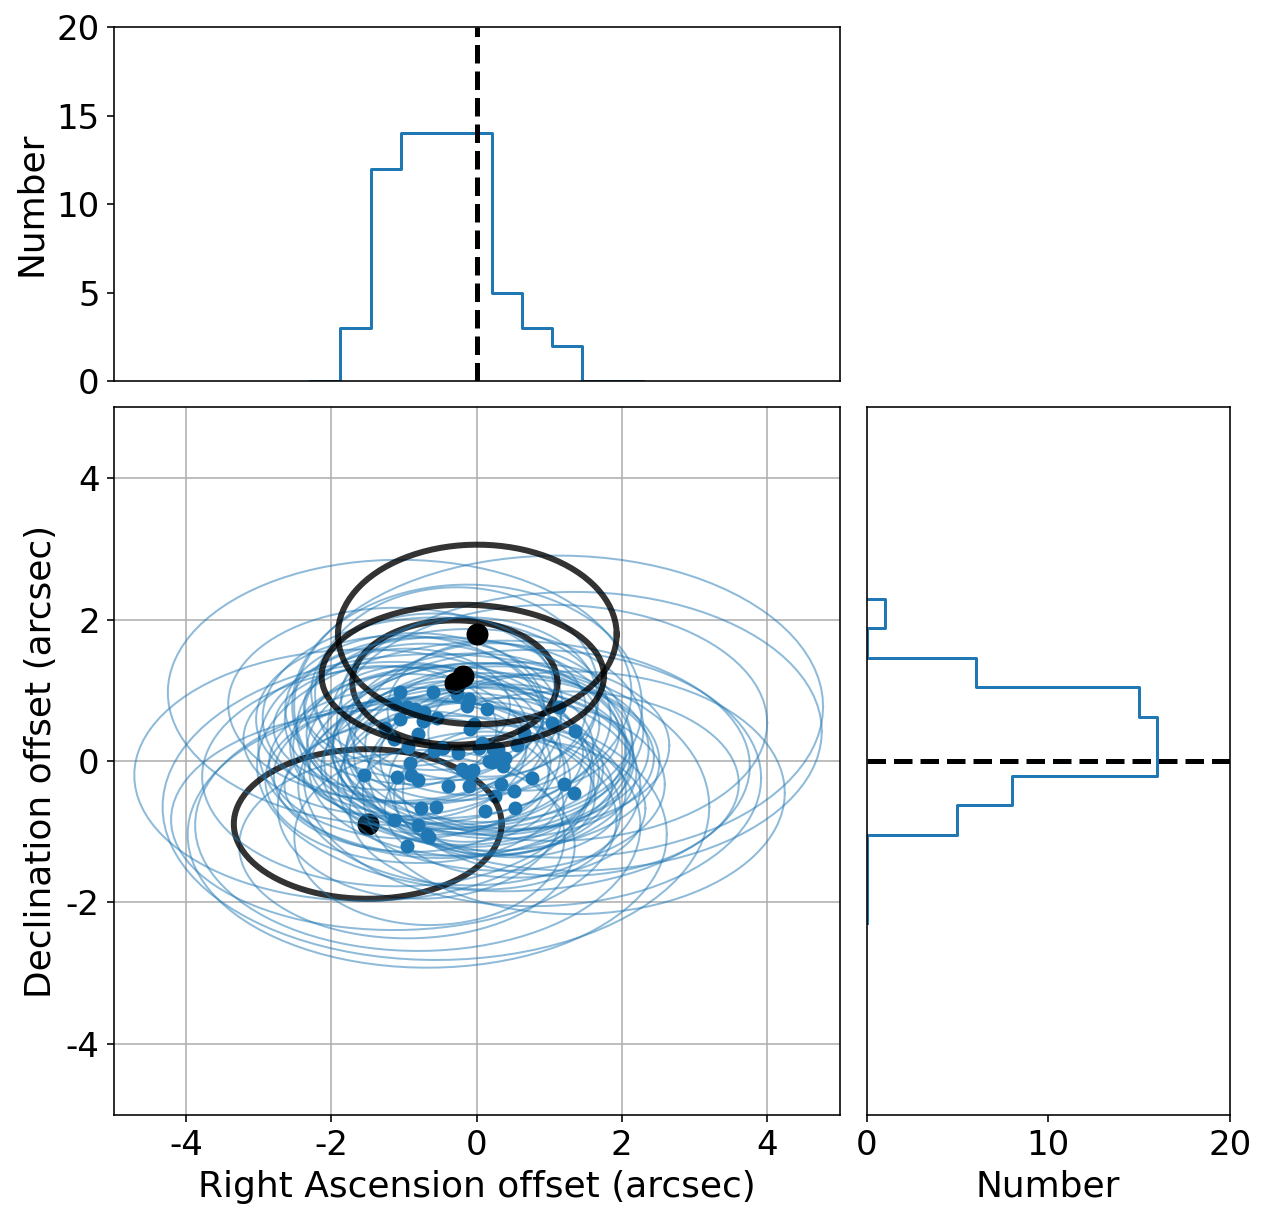

In [52]:
fig = plt.figure(figsize=(10,10))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1], height_ratios=[1, 2]) 
plt.subplots_adjust(wspace=0.05,hspace=0.05)

ax0 = plt.subplot(gs[0])
ax0.tick_params(axis='both', which='major', labelsize=17)
ax0.tick_params(bottom = False, labelbottom = False)
plt.xlim(-5.,5.)
plt.ylim(0,20)


y,xx = np.histogram(ra,bins=12,range=(-2.5,2.5))
x = 0.5*(xx[1:]+xx[:-1])
plt.step(x,y)
plt.plot([0.,0.],[0.,20.],'k--',lw=2.5)
plt.ylabel("Number",fontsize=18)

ax1 = plt.subplot(gs[2])
ax1.tick_params(axis='both', which='major', labelsize=17)
plt.xlim(-5.,5.)
plt.ylim(-5.,5.)
plt.grid()
#plt.errorbar(ra,de,fmt=".",color="black",xerr=ra_t,yerr=de_t,ecolor="black",elinewidth=1.5)
#plt.errorbar(ra,de,fmt="o",color="orange",xerr=rae,yerr=dee,ecolor="orange",elinewidth=2.5,capsize=10.)

for i in np.arange(len(ra)):
    uu=ra[i]     #x-position of the center
    v=de[i]    #y-position of the center
    a=ra_t[i]*2.14    #radius on the x-axis
    b=de_t[i]*2.14   #radius on the y-axis
    t = np.linspace(0, 2*np.pi, 100)
    x_el = uu+a*np.cos(t)
    y_el = v+b*np.sin(t)
    
    tt = np.arctan(de[i]/ra[i])+np.pi
    dist = np.sqrt(ra[i]**2.+de[i]**2.)
    if dist>np.sqrt((uu+a*np.cos(tt)-ra[i])**2.+(v+b*np.sin(tt)-de[i])**2.): 
        plt.plot(x_el,y_el,color='black',lw=3,alpha=0.8)
        plt.plot(ra[i],de[i],'o',color="black",markersize=10)
    else:
        plt.plot(x_el,y_el,color='tab:blue',lw=1.,alpha=0.5)
        plt.plot(ra[i],de[i],'o',color="tab:blue",markersize=6)
        


plt.xlabel("Right Ascension offset (arcsec)",fontsize=18)
plt.ylabel("Declination offset (arcsec)",fontsize=18)
    

ax2 = plt.subplot(gs[3])
ax2.tick_params(axis='both', which='major', labelsize=17)
ax2.tick_params(left = False, labelleft = False) 
plt.ylim(-5.,5.)
plt.xlim(0,20)



y,xx = np.histogram(de,bins=12,range=(-2.5,2.5))
x = 0.5*(xx[1:]+xx[:-1])
plt.step(y,x)
plt.plot([0.,20.],[0.,0.],'k--',lw=2.5)
plt.xlabel("Number",fontsize=18)

Text(0, 0.5, 'Total offset (arcsec)')

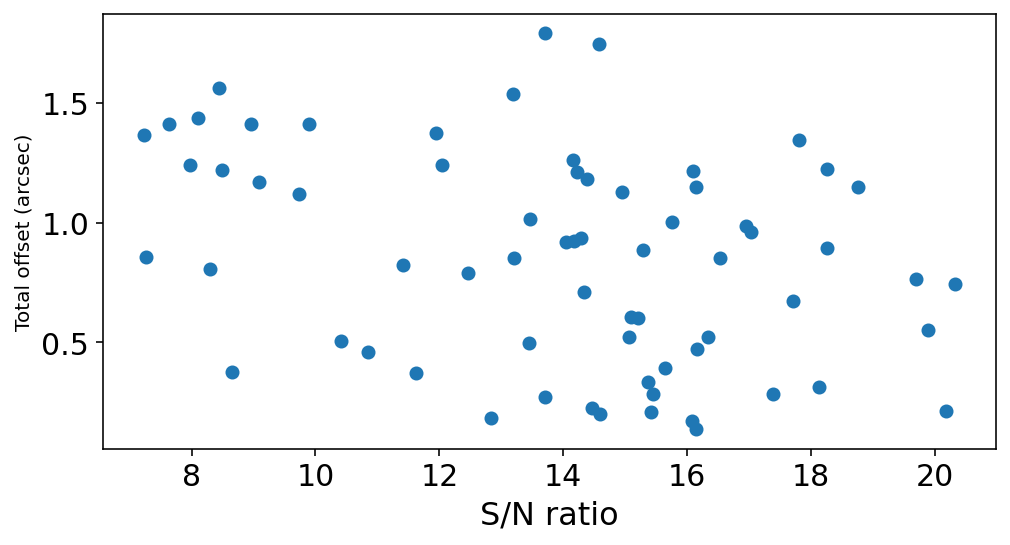

In [57]:
plt.figure(figsize=(8,4))
plt.tick_params(axis='both', which='major', labelsize=15)
plt.scatter(sn,np.sqrt(ra**2.+de**2.))
plt.xlabel("S/N ratio",fontsize=16)
plt.ylabel("Total offset (arcsec)")